# Block 5: Are my tower years normal?
Frieda Mohr, 2026-11-24

In [2]:
# packages 

import os, sys
import zipfile
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

ROOT = Path.cwd().parent if Path.cwd().name == "reports" else Path.cwd()
os.chdir(ROOT)

## E1. Question and hypothesis

**Question:** How far does each tower year's mean air temperature and annual precipitation deviate from the WorldClim 1970–2000 climate normal (BIO1, BIO12)?

**Motivation:** In the Block 4 data summary, the annual precipitation sums at two towers looked not realistic: at JP-NsC, 2600–7100 mm per year in 2004–2012, followed by an abrupt drop to about 1400–1600 mm from 2013 onward, and at AU-APL 3500–5700 mm per year, about twice what is expected for the Australian Alps. Comparing the tower years with the long-term climate normal, and with an independent reanalysis (ERA5-Land), is a way to find out whether these years were truly unusual or whether the tower records are wrong.

**Hypothesis:**
1. *Temperature:* The tower years are warmer than the 1970–2000 normal, by roughly 0.5–1.5 °C, because the tower records (2003–2022) fall into a period of ongoing climate warming.
2. *Precipitation:* Annual precipitation at most towers stays within about ±30 % of the normal, since year-to-year variability rarely exceeds this range over many consecutive years. The much larger deviations at JP-NsC (2004–2012) and AU-APL are expected to result from measurement errors in the tower record. If so, ERA5-Land should show near-normal precipitation in the same years.

**Are the five towers a good test?** The towers span five ecosystems on four continents and records of 6 to 18 years, so they cover a wide range of climates and include both apparently plausible and implausible precipitation records, which allows a direct comparison. Limitations are that WorldClim (~9 km) and ERA5-Land (~9 km) describe the climate of a large grid cell rather than the tower location itself, which matters most at the mountain sites IT-Lav and AU-APL, and that the normal period (1970–2000) does not overlap with any of the tower records.

## E2. Data 

| Dataset | Variables used | Spatial resolution | Time resolution and period | Downloaded on | Script and changes | Citation |
| --- | --- | --- | --- | --- | --- | --- |
| FLUXNET (ONEFlux v1.3, FLUXMET_HH) | `TA_F`, `TA_F_QC`, `P_F`, `P_F_QC` | tower footprint (about 100 m – 1 km) | half-hourly; AU-APL 2017–2022, CN-Yuc 2011–2020, IT-Lav 2003–2020, JP-NsC 2004–2015, US-ChR 2006–2019 | 23.11.2026 (local re-download; first download on 17.11.2026 on bwUniCluster) | `scripts/get_my_towers.py --student 17`, unchanged; snapshot `fluxnet_shuttle_snapshot_20261123T150018.csv` | site citations (E6); Pastorello et al. (2020) |
| WorldClim 2.1 | BIO1 (mean annual temperature, °C), BIO12 (annual precipitation, mm) | 5′ (about 9 km) | climate normal 1970–2000 (one value per tower) | 23.11.2026 | `scripts/block5/02_worldclim.py`, unchanged | Fick & Hijmans (2017) |
| ERA5-Land hourly time series | `2m_temperature` (°C), `total_precipitation` (m) | 0.1° (about 9 km), nearest grid cell | hourly; last ten years of each tower record (AU-APL 2017–2022, CN-Yuc 2011–2020, IT-Lav 2011–2020, JP-NsC 2006–2015, US-ChR 2010–2019) | 23.11.2026 | `scripts/block5/01_era5land.py`; variables reduced to air temperature and precipitation (soil variables not needed), `YEARS_BACK = 10` unchanged | Muñoz-Sabater et al. (2021); contains modified Copernicus Climate Change Service information 2026 |

**The two datasets at the five towers.** The WorldClim normals range from 6.4 °C and 1599 mm at the alpine peatland AU-APL to 13.9 °C and 1226 mm at US-ChR, with the driest normal at CN-Yuc (607 mm) and IT-Lav (621 mm). ERA5-Land provides 6 to 10 complete years per tower. Its mean annual temperature is 0.5–1.5 °C higher than the WorldClim normal at four towers and about 1.5 °C lower at JP-NsC, and its mean annual precipitation is close to the normal at CN-Yuc and US-ChR, about 20 % below it at AU-APL and 40–140 % above it at JP-NsC and IT-Lav. Both datasets describe the climate of a grid cell of about 9 km, i.e. an area roughly 10–100 times larger than the flux footprint.

## E3. Methods

### Download

All data were downloaded on my laptop on 23 November 2026, running the scripts from the project folder in a Python virtual environment.

- **FLUXNET:** The five tower records were downloaded with `scripts/get_my_towers.py --student 17` (unchanged), which uses the FLUXNET Shuttle and also writes a snapshot of all available FLUXNET data to `data/snapshots/`. The data had already been downloaded for Block 4 on the bwUniCluster, but the cluster was unavailable during this assignment because of a scheduled shutdown of all HPC systems at KIT (23 November – 4 December 2026). I therefore downloaded the data a second time to my laptop; the file versions (v1.3_r1/r2) are the same as in Block 4.
- **WorldClim:** `scripts/block5/02_worldclim.py` was run unchanged with the default resolution of 5′ (about 9 km). A finer resolution (30″, about 1 km) would describe the mountain sites better but requires downloading about 10 GB.
- **ERA5-Land:** `scripts/block5/01_era5land.py` was run after creating an account at the Copernicus Climate Data Store, accepting the ERA5-Land licence and storing the personal access token in `~/.cdsapirc`. I changed the list of variables to `2m_temperature` and `total_precipitation` only, because the question needs air temperature and precipitation, not the soil variables included by default; fewer variables also shorten the requests. The number of years was left at `YEARS_BACK = 10`, so ERA5-Land covers the last ten years of each tower record (all six years at AU-APL). For JP-NsC, this period (2006–2015) includes both the years with implausible tower precipitation and the measured years from 2012 onward. The requests were processed by the CDS within a few minutes and the download ran without errors.

### Processing Fluxnet

In [3]:
import zipfile

keep = ["TIMESTAMP_START", "TA_F", "TA_F_QC", "P_F", "P_F_QC"]

def read_met(zip_file):
    """Read temperature and precipitation (with QC flags) from one FLUXNET zip."""
    zip_file = Path(zip_file)
    site = zip_file.name.split("_")[1]
    with zipfile.ZipFile(zip_file) as z:
        name = [n for n in z.namelist() if "FLUXMET_HH" in n][0]
        with z.open(name) as f:
            d = pd.read_csv(f, na_values=[-9999], usecols=lambda c: c in keep,
                            dtype={"TIMESTAMP_START": str})
    d["time"] = pd.to_datetime(d["TIMESTAMP_START"], format="%Y%m%d%H%M")
    d.insert(0, "site_id", site)
    return d

met = pd.concat([read_met(z) for z in sorted(Path("data/raw").glob("*.zip"))],
                ignore_index=True)
met["year"] = met["time"].dt.year

# Annual values per tower
tower_year = met.groupby(["site_id", "year"]).agg(
    P_tower=("P_F", "sum"),                                   # mm per year
    P_measured_share=("P_F_QC", lambda q: (q == 0).mean()),   # share of half hours measured
    TA_tower=("TA_F", "mean"),                                # °C
    TA_measured_share=("TA_F_QC", lambda q: (q == 0).mean()),
    n=("P_F", "size"),
).reset_index()

tower_year.round(2)

,site_id,year,P_tower,P_measured_share,TA_tower,TA_measured_share,n
0,AU-APL,2017,4105.68,0.00,5.84,0.62,17520
1,AU-APL,2018,3568.23,0.00,6.24,0.83,17520
2,AU-APL,2019,3485.15,0.00,6.54,0.87,17520
3,AU-APL,2020,4778.50,0.00,6.07,0.81,17568
4,AU-APL,2021,5013.12,0.00,5.29,0.83,17520
5,AU-APL,2022,5679.06,0.00,5.79,0.39,17520
6,CN-Yuc,2011,399.60,1.00,12.56,1.00,17520
7,CN-Yuc,2012,536.80,1.00,12.85,1.00,17568
8,CN-Yuc,2013,633.00,1.00,13.04,0.97,17520
9,CN-Yuc,2014,252.80,1.00,13.67,0.98,17520


Half-hourly air temperature (`TA_F`, °C) and precipitation (`P_F`, mm per half hour) were read from the `FLUXMET_HH` file in each FLUXNET zip, with −9999 treated as missing. Annual precipitation was calculated as the sum of all half-hourly values and annual temperature as the mean. The quality flags `P_F_QC` and `TA_F_QC` were used to compute the share of half hours per year that were actually measured at the tower (QC = 0); all other half hours were gap-filled by ONEFlux with downscaled ERA5 data. All tower years have a complete set of half hours (17,520 or 17,568).

### Processing: ERA5-Land

In [4]:
h = pd.read_csv("data/external/era5land/AU-APL_era5land_hourly.csv")
h[["valid_time", "tp"]].iloc[0:50]

,valid_time,tp
0,2017-01-01 00:00:00,0.000000e+00
1,2017-01-01 01:00:00,0.000000e+00
2,2017-01-01 02:00:00,0.000000e+00
3,2017-01-01 03:00:00,0.000000e+00
4,2017-01-01 04:00:00,0.000000e+00
5,2017-01-01 05:00:00,0.000000e+00
6,2017-01-01 06:00:00,0.000000e+00
7,2017-01-01 07:00:00,5.364418e-07
8,2017-01-01 08:00:00,5.215406e-08
9,2017-01-01 09:00:00,1.563877e-05


In [5]:
era = pd.concat([pd.read_csv(f) for f in
                 sorted(Path("data/external/era5land").glob("*_era5land_hourly.csv"))],
                ignore_index=True)
era["valid_time"] = pd.to_datetime(era["valid_time"])
era["year"] = era["valid_time"].dt.year
era["tp_mm"] = era["tp"].clip(lower=0) * 1000      # m -> mm, remove tiny negative noise

era_year = era.groupby(["site_id", "year"]).agg(
    P_era5land=("tp_mm", "sum"),          # mm per year
    TA_era5land=("t2m_C", "mean"),        # °C
    n_hours=("tp_mm", "size"),
).reset_index()
era_year = era_year[era_year["n_hours"] >= 8760]   # complete years only

era_year.round(1)

,site_id,year,P_era5land,TA_era5land,n_hours
0,AU-APL,2017,1139.1,7.9,8760
1,AU-APL,2018,1020.5,7.9,8760
2,AU-APL,2019,999.0,8.3,8760
3,AU-APL,2020,1345.0,7.9,8784
4,AU-APL,2021,1408.1,7.2,8760
5,AU-APL,2022,1568.0,7.2,8760
6,CN-Yuc,2011,576.3,13.8,8760
7,CN-Yuc,2012,533.7,14.0,8784
8,CN-Yuc,2013,617.7,14.4,8760
9,CN-Yuc,2014,438.3,15.2,8760


ERA5-Land hourly air temperature (`t2m`, converted by the script to °C) and total precipitation (`tp`, m) were read for the nearest grid cell of each tower. Inspection of the hourly values showed that the time-series product provides hourly precipitation amounts rather than values accumulated over the day, so annual precipitation was calculated as the sum of all hourly values (converted to mm; tiny negative values from numerical noise set to 0). Only complete years (≥ 8,760 hours) were kept. ERA5-Land time stamps are in UTC, while the tower data are in local standard time; this shift of a few hours is negligible for annual values.

### Processing: WorldClim

In [7]:
wc = pd.read_csv("data/external/worldclim/worldclim_bio_my_sites.csv")
wc = wc[["site_id", "igbp", "lat", "lon", "BIO1", "BIO12"]]
wc.round(1)

,site_id,igbp,lat,lon,BIO1,BIO12
0,US-ChR,DBF,35.9,-84.3,13.9,1226.0
1,IT-Lav,ENF,46.0,11.3,8.1,621.0
2,JP-NsC,GRA,36.9,139.9,12.3,1322.0
3,CN-Yuc,CRO,36.8,116.6,13.1,607.0
4,AU-APL,WET,-36.9,147.3,6.4,1599.0


WorldClim 2.1 bioclimatic variables at 5′ resolution (about 9 km) were extracted by the script `02_worldclim.py` for the grid cell containing each tower (nearest cell, coordinates in WGS84/EPSG:4326). Two variables were used: BIO1, the mean annual air temperature (°C), and BIO12, the annual precipitation (mm), both as averages over 1970–2000. This gives one normal value per tower and variable. The deviation of each tower year (and each ERA5-Land year) from the normal was calculated as the difference in °C for temperature and as the relative deviation in % for precipitation:

ΔT = T_year − BIO1, ΔP = (P_year / BIO12 − 1) · 100 %.

### Merging

In [8]:
df = (tower_year
      .merge(era_year.drop(columns="n_hours"), on=["site_id", "year"], how="left")
      .merge(wc[["site_id", "BIO1", "BIO12"]], on="site_id", how="left"))

# Deviations from the 1970–2000 normal
df["dT_tower"] = df["TA_tower"] - df["BIO1"]                       # °C
df["dT_era5land"] = df["TA_era5land"] - df["BIO1"]                 # °C
df["dP_tower_pct"] = (df["P_tower"] / df["BIO12"] - 1) * 100       # %
df["dP_era5land_pct"] = (df["P_era5land"] / df["BIO12"] - 1) * 100 # %

# Was precipitation mostly measured at the tower in this year?
df["P_measured"] = df["P_measured_share"] >= 0.9

df.round(1)

,site_id,year,P_tower,P_measured_share,TA_tower,TA_measured_share,n,P_era5land,TA_era5land,BIO1,BIO12,dT_tower,dT_era5land,dP_tower_pct,dP_era5land_pct,P_measured
0,AU-APL,2017,4105.7,0.0,5.8,0.6,17520,1139.1,7.9,6.4,1599.0,-0.6,1.4,156.8,-28.8,False
1,AU-APL,2018,3568.2,0.0,6.2,0.8,17520,1020.5,7.9,6.4,1599.0,-0.2,1.4,123.2,-36.2,False
2,AU-APL,2019,3485.1,0.0,6.5,0.9,17520,999.0,8.3,6.4,1599.0,0.1,1.8,118.0,-37.5,False
3,AU-APL,2020,4778.5,0.0,6.1,0.8,17568,1345.0,7.9,6.4,1599.0,-0.4,1.5,198.8,-15.9,False
4,AU-APL,2021,5013.1,0.0,5.3,0.8,17520,1408.1,7.2,6.4,1599.0,-1.2,0.8,213.5,-11.9,False
5,AU-APL,2022,5679.1,0.0,5.8,0.4,17520,1568.0,7.2,6.4,1599.0,-0.7,0.8,255.2,-1.9,False
6,CN-Yuc,2011,399.6,1.0,12.6,1.0,17520,576.3,13.8,13.1,607.0,-0.6,0.7,-34.2,-5.1,True
7,CN-Yuc,2012,536.8,1.0,12.8,1.0,17568,533.7,14.0,13.1,607.0,-0.3,0.8,-11.6,-12.1,True
8,CN-Yuc,2013,633.0,1.0,13.0,1.0,17520,617.7,14.4,13.1,607.0,-0.1,1.2,4.3,1.8,True
9,CN-Yuc,2014,252.8,1.0,13.7,1.0,17520,438.3,15.2,13.1,607.0,0.5,2.0,-58.4,-27.8,True


The annual tower values, the annual ERA5-Land values and the WorldClim normals were joined into one table by `site_id` and `year` (WorldClim by `site_id` only, since it provides one value per tower). ERA5-Land covers only the last ten years of each tower record; in earlier years its columns are empty (NA). A tower year is labelled as having measured precipitation if at least 90 % of its half hours were measured (`P_F_QC` = 0); all other years consist mainly of gap-filled ERA5 values.

## E4. Results

### Precipitation

In [9]:
df["P_ratio"] = df["P_tower"] / df["P_era5land"]

summary = (df.groupby(["site_id", "P_measured"])
             .agg(n_years=("year", "size"),
                  dT_tower=("dT_tower", "mean"),
                  dT_era5land=("dT_era5land", "mean"),
                  dP_tower_pct=("dP_tower_pct", "mean"),
                  dP_era5land_pct=("dP_era5land_pct", "mean"),
                  P_ratio_mean=("P_ratio", "mean"),
                  P_ratio_n=("P_ratio", "count"))
             .reset_index())
summary.round(2)

,site_id,P_measured,n_years,dT_tower,dT_era5land,dP_tower_pct,dP_era5land_pct,P_ratio_mean,P_ratio_n
0,AU-APL,False,6,-0.48,1.29,177.57,-22.04,3.55,6
1,CN-Yuc,False,1,0.99,2.26,-33.99,-22.13,0.85,1
2,CN-Yuc,True,9,0.38,1.51,-20.73,-6.04,0.83,9
3,IT-Lav,False,8,-0.93,0.53,65.40,88.20,0.75,2
4,IT-Lav,True,10,-0.45,0.71,91.16,139.06,0.78,8
5,JP-NsC,False,8,-0.16,-1.50,183.79,50.26,1.99,6
6,JP-NsC,True,4,-0.23,-1.66,62.68,41.17,1.14,4
7,US-ChR,True,14,1.01,1.64,13.52,11.27,1.08,10


**Summary** At the two towers with implausible precipitation, the ratio of tower to ERA5-Land annual precipitation is almost constant in the gap-filled years: 3.55 at AU-APL (range 3.5–3.6, n = 6 years) and 1.68 at JP-NsC in 2006–2010 (range 1.66–1.70, n = 5 years). In years with measured precipitation, the ratio is close to 1 at all towers: 0.78–0.84 at JP-NsC in 2013–2015 (n = 3), 0.83 at CN-Yuc (n = 9), 0.78 at IT-Lav (n = 8) and 1.08 at US-ChR (n = 10). Exceptions are JP-NsC 2011 (ratio 3.55, 47 % measured) and 2012 (2.12, measured).

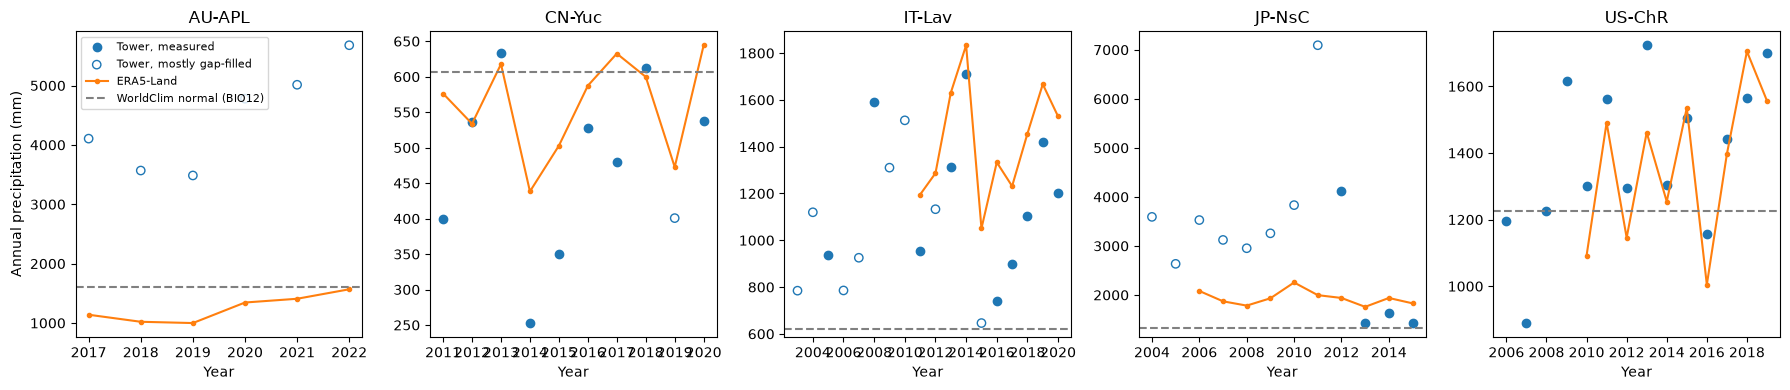

In [11]:
sites = sorted(df["site_id"].unique())
fig, axes = plt.subplots(1, len(sites), figsize=(18, 4), sharey=False)
for ax, site in zip(axes, sites):
    d = df[df["site_id"] == site]
    meas, fill = d[d["P_measured"]], d[~d["P_measured"]]
    ax.scatter(meas["year"], meas["P_tower"], color="tab:blue", label="Tower, measured")
    ax.scatter(fill["year"], fill["P_tower"], facecolors="none", edgecolors="tab:blue",
               label="Tower, mostly gap-filled")
    ax.plot(d["year"], d["P_era5land"], color="tab:orange", marker=".", label="ERA5-Land")
    ax.axhline(d["BIO12"].iloc[0], color="grey", ls="--", label="WorldClim normal (BIO12)")
    ax.set_title(site)
    ax.set_xlabel("Year")
    ax.xaxis.set_major_locator(plt.MaxNLocator(integer=True))
axes[0].set_ylabel("Annual precipitation (mm)")
axes[0].legend(fontsize=8)
plt.tight_layout()
plt.show()

Figure 1 shows the annual precipitation at the five towers. Filled circles: tower years with ≥ 90 % measured half hours; open circles: tower years consisting mainly of gap-filled ERA5 values; orange line: ERA5-Land (last ten years of each record); dashed line: WorldClim 1970–2000 normal (BIO12). Note the different y-axis ranges.

In years with measured precipitation, the tower and ERA5-Land annual sums agree within about ±25 %, and at CN-Yuc and US-ChR both lie close to the WorldClim normal (mean deviation of measured tower years −21 % and +14 %). At AU-APL, ERA5-Land is close to or slightly below the normal (mean −22 %), whereas the gap-filled tower record is 3.5 times higher (+178 %). At JP-NsC, ERA5-Land lies 33–71 % above the normal in all years, while the gap-filled tower years 2006–2010 exceed ERA5-Land by a constant factor of 1.7. At IT-Lav, both the measured tower values and ERA5-Land lie far above the WorldClim normal of 621 mm (mean +91 % and +139 %).

### Airtemperature

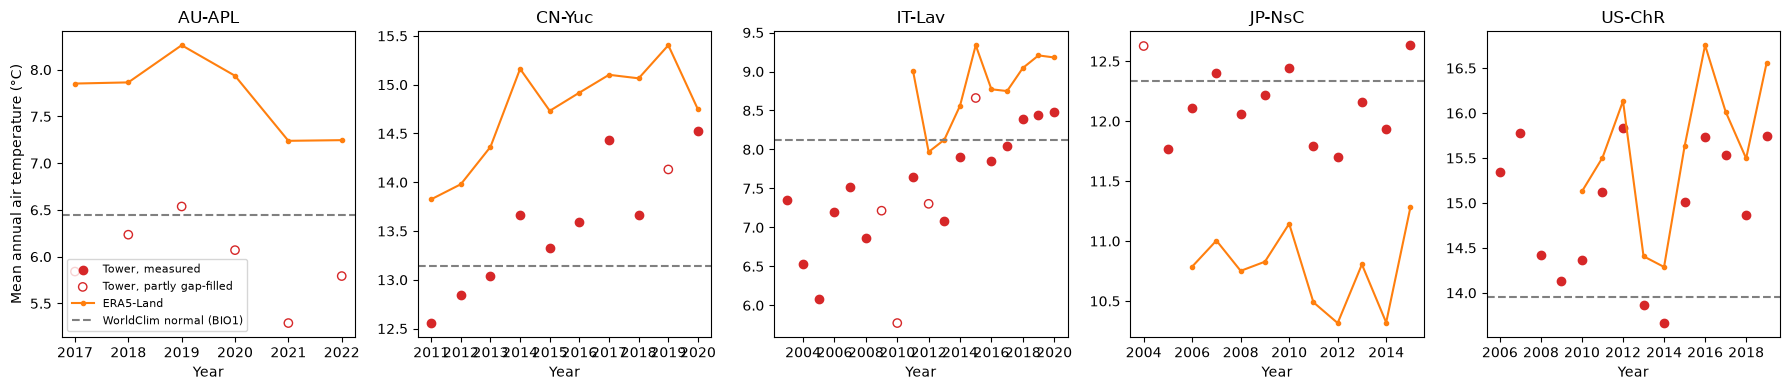

In [13]:
df["TA_measured"] = df["TA_measured_share"] >= 0.9

fig, axes = plt.subplots(1, len(sites), figsize=(18, 4), sharey=False)
for ax, site in zip(axes, sites):
    d = df[df["site_id"] == site]
    meas, fill = d[d["TA_measured"]], d[~d["TA_measured"]]
    ax.scatter(meas["year"], meas["TA_tower"], color="tab:red", label="Tower, measured")
    ax.scatter(fill["year"], fill["TA_tower"], facecolors="none", edgecolors="tab:red",
               label="Tower, partly gap-filled")
    ax.plot(d["year"], d["TA_era5land"], color="tab:orange", marker=".", label="ERA5-Land")
    ax.axhline(d["BIO1"].iloc[0], color="grey", ls="--", label="WorldClim normal (BIO1)")
    ax.set_title(site)
    ax.set_xlabel("Year")
    ax.xaxis.set_major_locator(plt.MaxNLocator(integer=True))
axes[0].set_ylabel("Mean annual air temperature (°C)")
axes[0].legend(fontsize=8)
plt.tight_layout()
plt.show()

Figure 2 shows the mean annual air temperature at the five towers. Filled circles: tower years with ≥ 90 % measured half hours; open circles: tower years with more than 10 % gap-filled half hours; orange line: ERA5-Land (last ten years of each record); dashed line: WorldClim 1970–2000 normal (BIO1). Note the different y-axis ranges.

The temperature hypothesis is clearly supported only at the lowland sites. At US-ChR, almost all tower years were warmer than the 1970–2000 normal (mean deviation +1.0 °C, n = 14 years), and at CN-Yuc the tower temperature rose from 12.6 °C (2011) to 14.5 °C (2020), with most years above the normal (mean +0.4 °C, n = 9 measured years). At IT-Lav, the tower years were mostly colder than the normal (mean −0.5 °C for measured years), but the record shows a warming from about 6–7.5 °C before 2010 to 8.4–8.5 °C in 2018–2020, i.e. the most recent years exceed the normal. At JP-NsC (mean −0.2 °C) and AU-APL (−0.5 °C), the tower temperatures lie close to or slightly below the normal. ERA5-Land differs from the tower by an almost constant offset at each site: it is warmer by about 0.6 °C (US-ChR) to 1.8 °C (AU-APL) at four towers and colder by about 1.5 °C at JP-NsC. Such a constant offset points to a difference in elevation or location between the tower and the ERA5-Land grid cell rather than to a climate signal.

In [ ]:
# description of the datasets
desc = (df.groupby("site_id")
          .agg(BIO1=("BIO1", "first"), BIO12=("BIO12", "first"),
               TA_era5land_mean=("TA_era5land", "mean"),
               P_era5land_mean=("P_era5land", "mean"),
               era5land_years=("P_era5land", "count"))
          .merge(wc[["site_id", "igbp", "lat", "lon"]], on="site_id")
          .round(1))
desc

,site_id,BIO1,BIO12,TA_era5land_mean,P_era5land_mean,era5land_years,igbp,lat,lon
0,AU-APL,6.4,1599.0,7.7,1246.6,6,WET,-36.9,147.3
1,CN-Yuc,13.1,607.0,14.7,560.6,10,CRO,36.8,116.6
2,IT-Lav,8.1,621.0,8.8,1421.4,10,ENF,46.0,11.3
3,JP-NsC,12.3,1322.0,10.8,1938.4,10,GRA,36.9,139.9
4,US-ChR,13.9,1226.0,15.6,1364.2,10,DBF,35.9,-84.3


The quality flags show that precipitation was never measured at AU-APL (0 % measured half hours in all years 2017–2022), so its entire precipitation record consists of gap-filled ERA5 values. At JP-NsC, precipitation was not measured in 2004–2010 (0 %), partly measured in 2011 (47 %) and measured from 2012 onward. The implausibly high annual sums at these two sites (2,600–5,700 mm) therefore come almost entirely from gap-filled values, whereas the measured years at JP-NsC from 2013 onward (1,430–1,630 mm) are plausible. Exceptions are JP-NsC 2011 (7,093 mm) and 2012 (4,117 mm), where measured values are also very high. At CN-Yuc, IT-Lav and US-ChR, precipitation was measured in almost all years, and the few fully gap-filled years (CN-Yuc 2019, IT-Lav 2003) have plausible sums. Temperature was measured in most half hours at all towers.

## E5. Discussion

## E6. Data and citation